Downloading/loading Covertype dataset

DATASET SUMMARY
---------------------------------------------
Number of samples : 581,012
Number of features: 54
Number of classes : 7
Missing values    : 0
Target classes    : [1 2 3 4 5 6 7]

CLASS DISTRIBUTION


,Class,Count,Percentage
0,1,211840,36.46
1,2,283301,48.76
2,3,35754,6.15
3,4,2747,0.47
4,5,9493,1.63
5,6,17367,2.99
6,7,20510,3.53


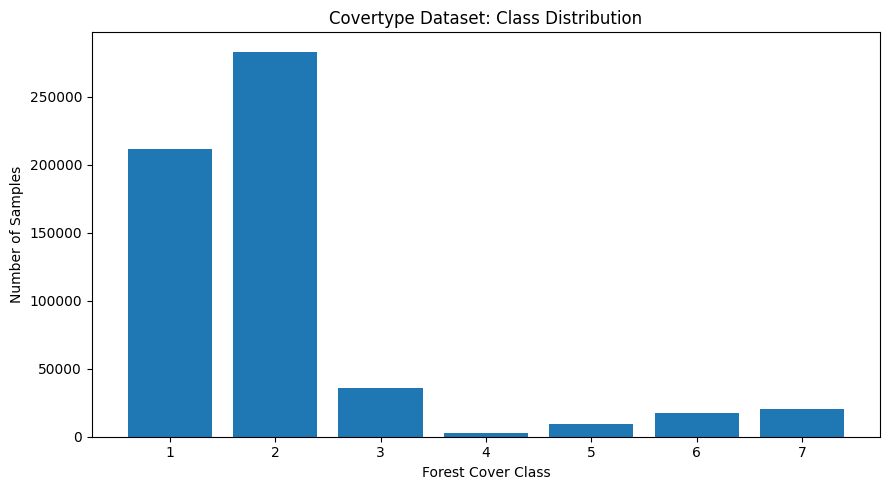


Imbalance ratio (largest/smallest class): 103.13:1


In [1]:
#loading & inspecting the covertype dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_covtype
from collections import Counter

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Downloading/loading Covertype dataset")
covtype = fetch_covtype()

X = covtype.data
y = covtype.target

print("\nDATASET SUMMARY")
print("-" * 45)
print(f"Number of samples : {X.shape[0]:,}")
print(f"Number of features: {X.shape[1]}")
print(f"Number of classes : {len(np.unique(y))}")
print(f"Missing values    : {np.isnan(X).sum():,}")
print(f"Target classes    : {np.unique(y)}")

class_counts = Counter(y)

distribution = pd.DataFrame({
    "Class": sorted(class_counts.keys()),
    "Count": [class_counts[c] for c in sorted(class_counts.keys())]
})

distribution["Percentage"] = (
    distribution["Count"] / len(y) * 100
).round(2)

print("\nCLASS DISTRIBUTION")
display(distribution)

plt.figure(figsize=(9, 5))
plt.bar(
    distribution["Class"].astype(str),
    distribution["Count"]
)
plt.title("Covertype Dataset: Class Distribution")
plt.xlabel("Forest Cover Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

imbalance_ratio = (
    distribution["Count"].max() /
    distribution["Count"].min()
)

print(f"\nImbalance ratio (largest/smallest class): "
      f"{imbalance_ratio:.2f}:1")

In [2]:
#creating reproducible train, validation, and test splits

from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

RANDOM_STATE = 42

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20, #separating 20% for the final test set
    random_state=RANDOM_STATE,
    stratify=y
)

#splitting the remaining 80% into training and validation.
#validation = 15% of the full dataset.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.1875,
    random_state=RANDOM_STATE,
    stratify=y_train_val
)

print("SPLIT SUMMARY")
print("-" * 45)
print(f"Training samples  : {len(y_train):,}")
print(f"Validation samples: {len(y_val):,}")
print(f"Test samples      : {len(y_test):,}")
print(f"Total samples     : {len(y_train) + len(y_val) + len(y_test):,}")

print("\nCLASS COUNTS PER SPLIT")

split_counts = pd.DataFrame({
    "Train": pd.Series(y_train).value_counts().sort_index(),
    "Validation": pd.Series(y_val).value_counts().sort_index(),
    "Test": pd.Series(y_test).value_counts().sort_index()
}).fillna(0).astype(int)

display(split_counts)

assert len(np.unique(y_train)) == 7
assert len(np.unique(y_val)) == 7
assert len(np.unique(y_test)) == 7

print("\nAll seven classes are present in every split.")
print("Split completed successfully.")

SPLIT SUMMARY
---------------------------------------------
Training samples  : 377,657
Validation samples: 87,152
Test samples      : 116,203
Total samples     : 581,012

CLASS COUNTS PER SPLIT


,Train,Validation,Test
1,137696,31776,42368
2,184145,42495,56661
3,23240,5363,7151
4,1786,412,549
5,6170,1424,1899
6,11289,2605,3473
7,13331,3077,4102



All seven classes are present in every split.
Split completed successfully.


TRAINING CLASS COUNTS


,Natural,Moderate,Severe
Forest Cover Class,,,
1,137696,68848,27539
2,184145,184145,184145
3,23240,11620,4648
4,1786,893,357
5,6170,3085,1234
6,11289,5644,2257
7,13331,6665,2666



TOTAL TRAINING SAMPLES
Natural : 377657
Moderate: 280900
Severe  : 222846


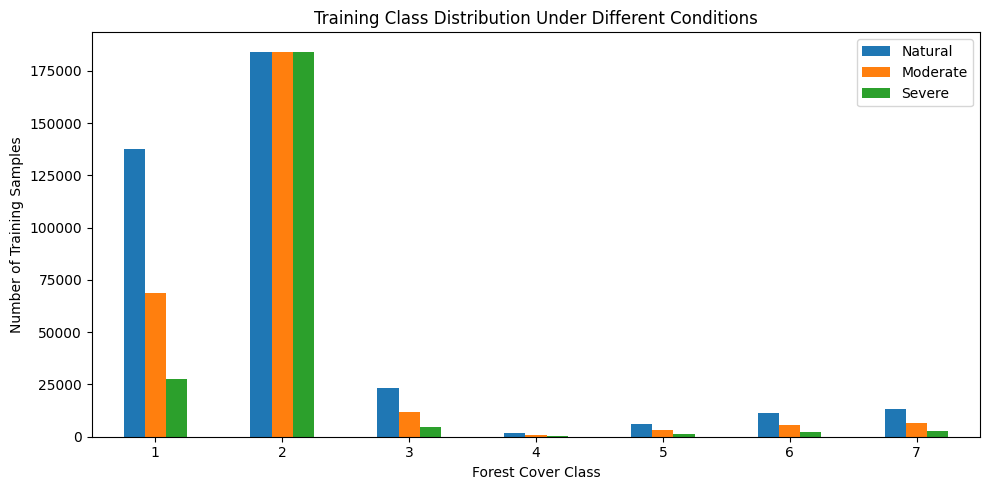


Validation and test sets remain unchanged.


In [3]:
#creating controlled training imbalance

import numpy as np
import pandas as pd
from collections import Counter

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

X_train_natural = X_train.copy()
y_train_natural = y_train.copy()

#class 1 is the majority class in covertype
#we retain all its training examples and progressively reduce
majority_class = Counter(y_train).most_common(1)[0][0]

def create_imbalanced_training_set(X_data, y_data, minority_fraction):

    X_data = np.asarray(X_data)
    y_data = np.asarray(y_data)

    local_rng = np.random.default_rng(RANDOM_STATE)
    selected_indices = []

    for cls in np.unique(y_data):
        class_indices = np.where(y_data == cls)[0]

        if cls == majority_class:
            chosen = class_indices
        else:
            n_keep = max(1, int(len(class_indices) * minority_fraction))
            chosen = local_rng.choice(
                class_indices,
                size=n_keep,
                replace=False
            )

        selected_indices.extend(chosen.tolist())

    selected_indices = np.array(selected_indices)
    local_rng.shuffle(selected_indices)

    return X_data[selected_indices], y_data[selected_indices]

#moderate and severe conditions
X_train_moderate, y_train_moderate = create_imbalanced_training_set(
    X_train, y_train, minority_fraction=0.50
)

X_train_severe, y_train_severe = create_imbalanced_training_set(
    X_train, y_train, minority_fraction=0.20
)

def get_class_counts(y_values):
    counts = Counter(y_values)
    return {cls: counts.get(cls, 0) for cls in range(1, 8)}

comparison = pd.DataFrame({
    "Natural": get_class_counts(y_train_natural),
    "Moderate": get_class_counts(y_train_moderate),
    "Severe": get_class_counts(y_train_severe)
})

comparison.index.name = "Forest Cover Class"

print("TRAINING CLASS COUNTS")
display(comparison)

print("\nTOTAL TRAINING SAMPLES")
print("Natural :", len(y_train_natural))
print("Moderate:", len(y_train_moderate))
print("Severe  :", len(y_train_severe))

comparison.plot(kind="bar", figsize=(10, 5))
plt.title("Training Class Distribution Under Different Conditions")
plt.xlabel("Forest Cover Class")
plt.ylabel("Number of Training Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nValidation and test sets remain unchanged.")

In [4]:
#standardizing features and prepare PyTorch tensors

import numpy as np
import torch

from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

#using the natural training distribution for our first baseline
X_train_base = np.asarray(X_train, dtype=np.float32)
X_val_base = np.asarray(X_val, dtype=np.float32)
X_test_base = np.asarray(X_test, dtype=np.float32)

#fit only on the training data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_base).astype(np.float32)
X_val_scaled = scaler.transform(X_val_base).astype(np.float32)
X_test_scaled = scaler.transform(X_test_base).astype(np.float32)

y_train_encoded = np.asarray(y_train, dtype=np.int64) - 1
y_val_encoded = np.asarray(y_val, dtype=np.int64) - 1
y_test_encoded = np.asarray(y_test, dtype=np.int64) - 1

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_encoded, dtype=torch.long)
y_val_tensor = torch.tensor(y_val_encoded, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_encoded, dtype=torch.long)

print("PREPROCESSING SUMMARY")
print("-" * 45)
print("Training features:", X_train_tensor.shape)
print("Validation features:", X_val_tensor.shape)
print("Test features:", X_test_tensor.shape)

print("\nLabel ranges:")
print("Training:", y_train_tensor.min().item(),
      "to", y_train_tensor.max().item())
print("Validation:", y_val_tensor.min().item(),
      "to", y_val_tensor.max().item())
print("Test:", y_test_tensor.min().item(),
      "to", y_test_tensor.max().item())

print("\nFirst 5 training feature means:")
print(np.round(X_train_scaled.mean(axis=0)[:5], 4))

print("\nFirst 5 training feature standard deviations:")
print(np.round(X_train_scaled.std(axis=0)[:5], 4))

print("\nPyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("\nPreprocessing completed.")

PREPROCESSING SUMMARY
---------------------------------------------
Training features: torch.Size([377657, 54])
Validation features: torch.Size([87152, 54])
Test features: torch.Size([116203, 54])

Label ranges:
Training: 0 to 6
Validation: 0 to 6
Test: 0 to 6

First 5 training feature means:
[-0. -0.  0. -0. -0.]

First 5 training feature standard deviations:
[0.9999 0.9998 1.0002 0.9999 0.9999]

PyTorch version: 2.11.0+cpu
GPU available: False

Preprocessing completed.


In [5]:
#creating pytorch datasets and dataloaders

from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 1024
RANDOM_STATE = 42

#helper function to scale a training set using the existing scaler and construct its PyTorch dataLoader
def make_training_loader(X_raw, y_raw, batch_size=BATCH_SIZE):
    X_raw = np.asarray(X_raw, dtype=np.float32)
    y_raw = np.asarray(y_raw, dtype=np.int64) - 1

    X_scaled = scaler.transform(X_raw).astype(np.float32)

    dataset = TensorDataset(
        torch.tensor(X_scaled, dtype=torch.float32),
        torch.tensor(y_raw, dtype=torch.long)
    )

    generator = torch.Generator()
    generator.manual_seed(RANDOM_STATE)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
        num_workers=0
    )

    return loader

#natural distribution training loader
train_loader = make_training_loader(X_train, y_train)

#controlled imbalance loaders
moderate_loader = make_training_loader(
    X_train_moderate, y_train_moderate
)

severe_loader = make_training_loader(
    X_train_severe, y_train_severe
)

#validation and test loaders: no shuffling
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DATALOADER SUMMARY")
print("-" * 45)

for name, loader in [
    ("Natural training", train_loader),
    ("Moderate training", moderate_loader),
    ("Severe training", severe_loader),
    ("Validation", val_loader),
    ("Test", test_loader)
]:
    print(
        f"{name:20s}: {len(loader.dataset):,} samples, "
        f"{len(loader):,} batches"
    )

#inspecting one batch
sample_X, sample_y = next(iter(train_loader))

print("\nONE TRAINING BATCH")
print("Feature shape:", sample_X.shape)
print("Label shape:", sample_y.shape)
print("Feature dtype:", sample_X.dtype)
print("Label dtype:", sample_y.dtype)

assert sample_X.shape[1] == 54
assert sample_X.shape[0] <= BATCH_SIZE
assert sample_y.min().item() >= 0
assert sample_y.max().item() <= 6

print("\nAll DataLoaders are ready.")

DATALOADER SUMMARY
---------------------------------------------
Natural training    : 377,657 samples, 369 batches
Moderate training   : 280,900 samples, 275 batches
Severe training     : 222,846 samples, 218 batches
Validation          : 87,152 samples, 86 batches
Test                : 116,203 samples, 114 batches

ONE TRAINING BATCH
Feature shape: torch.Size([1024, 54])
Label shape: torch.Size([1024])
Feature dtype: torch.float32
Label dtype: torch.int64

All DataLoaders are ready.


In [6]:
#defining the baseline neural network

import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class CoverTypeMLP(nn.Module):
    def __init__(self, input_dim=54, num_classes=7):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)

torch.manual_seed(42)

model = CoverTypeMLP().to(device)

print("MODEL ARCHITECTURE")
print("-" * 45)
print(model)

total_params = sum(
    parameter.numel() for parameter in model.parameters()
)

print(f"\nTotal trainable parameters: {total_params:,}")
print("Input features: 54")
print("Output classes: 7")
print("Device:", device)

#verify the forward pass
sample_batch = torch.randn(8, 54).to(device)

with torch.no_grad():
    sample_output = model(sample_batch)

print("\nTest input shape:", sample_batch.shape)
print("Test output shape:", sample_output.shape)

assert sample_output.shape == (8, 7)

print("\nModel definition and forward pass successful.")

MODEL ARCHITECTURE
---------------------------------------------
CoverTypeMLP(
  (network): Sequential(
    (0): Linear(in_features=54, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=7, bias=True)
  )
)

Total trainable parameters: 15,751
Input features: 54
Output classes: 7
Device: cpu

Test input shape: torch.Size([8, 54])
Test output shape: torch.Size([8, 7])

Model definition and forward pass successful.


Epoch 1/5 | Train Loss: 0.8790 | Train Acc: 0.6561 | Val Loss: 0.6745 | Val Acc: 0.7260
Epoch 2/5 | Train Loss: 0.6474 | Train Acc: 0.7341 | Val Loss: 0.6269 | Val Acc: 0.7386
Epoch 3/5 | Train Loss: 0.6105 | Train Acc: 0.7440 | Val Loss: 0.5969 | Val Acc: 0.7489
Epoch 4/5 | Train Loss: 0.5850 | Train Acc: 0.7530 | Val Loss: 0.5750 | Val Acc: 0.7574
Epoch 5/5 | Train Loss: 0.5644 | Train Acc: 0.7614 | Val Loss: 0.5613 | Val Acc: 0.7595

Training time: 0.48 minutes
Best validation loss: 0.5613


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.878970,0.656090,0.674498,0.726042
1,2,0.647377,0.734084,0.626876,0.738572
2,3,0.610471,0.744046,0.596899,0.748853
3,4,0.584966,0.753011,0.574995,0.757378
4,5,0.564361,0.761381,0.561316,0.759524


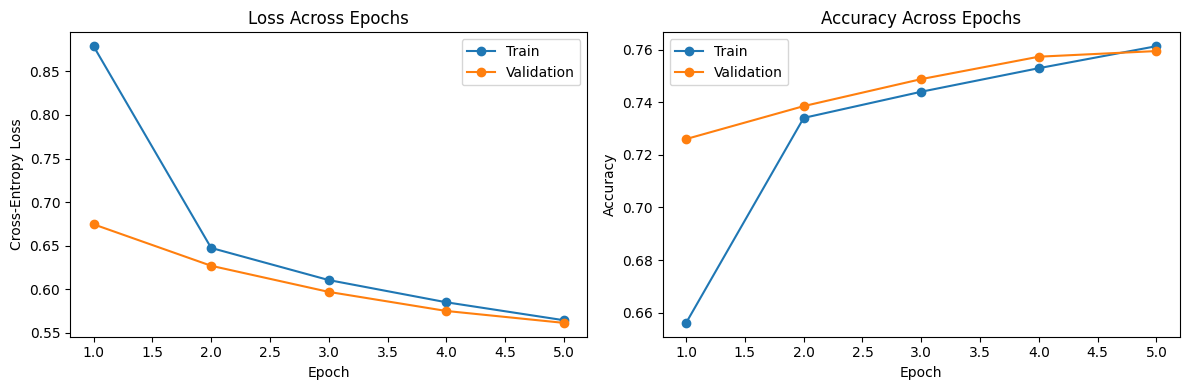


Baseline training completed.


In [7]:
#training the baseline MLP using ordinary SGD

import time
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import accuracy_score

torch.manual_seed(42)
np.random.seed(42)

#fresh model for a fair baseline
baseline_model = CoverTypeMLP().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    baseline_model.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=1e-4
)

EPOCHS = 5

history = []
best_val_loss = float("inf")
best_baseline_state = None

start_time = time.time()

for epoch in range(EPOCHS):
    baseline_model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for features, labels in train_loader:
        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = baseline_model(features)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        train_correct += (logits.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_accuracy = train_correct / train_total

    baseline_model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for features, labels in val_loader:
            features = features.to(device)
            labels = labels.to(device)

            logits = baseline_model(features)
            loss = criterion(logits, labels)

            val_running_loss += loss.item() * labels.size(0)
            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = val_correct / val_total

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_baseline_state = copy.deepcopy(
            baseline_model.state_dict()
        )

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

elapsed = time.time() - start_time

#restoring the model with the lowest validation loss
baseline_model.load_state_dict(best_baseline_state)

history_df = pd.DataFrame(history)

print(f"\nTraining time: {elapsed / 60:.2f} minutes")
print(f"Best validation loss: {best_val_loss:.4f}")

display(history_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"],
             marker="o", label="Train")
axes[0].plot(history_df["epoch"], history_df["val_loss"],
             marker="o", label="Validation")
axes[0].set_title("Loss Across Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["train_accuracy"],
             marker="o", label="Train")
axes[1].plot(history_df["epoch"], history_df["val_accuracy"],
             marker="o", label="Validation")
axes[1].set_title("Accuracy Across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

print("\nBaseline training completed.")

BASELINE VALIDATION RESULTS
--------------------------------------------------
Accuracy      : 0.7595
Macro-F1      : 0.5559
Weighted F1   : 0.7522
G-mean recall : 0.4249

CLASSIFICATION REPORT


,precision,recall,f1-score,support
Class 1,0.7410,0.7749,0.7576,31776.0000
Class 2,0.7995,0.7957,0.7976,42495.0000
Class 3,0.6623,0.8661,0.7506,5363.0000
Class 4,0.4974,0.2306,0.3151,412.0000
Class 5,0.7624,0.1081,0.1894,1424.0000
Class 6,0.5047,0.2660,0.3484,2605.0000
Class 7,0.7620,0.7056,0.7327,3077.0000
accuracy,0.7595,0.7595,0.7595,0.7595
macro avg,0.6756,0.5353,0.5559,87152.0000
weighted avg,0.7575,0.7595,0.7522,87152.0000


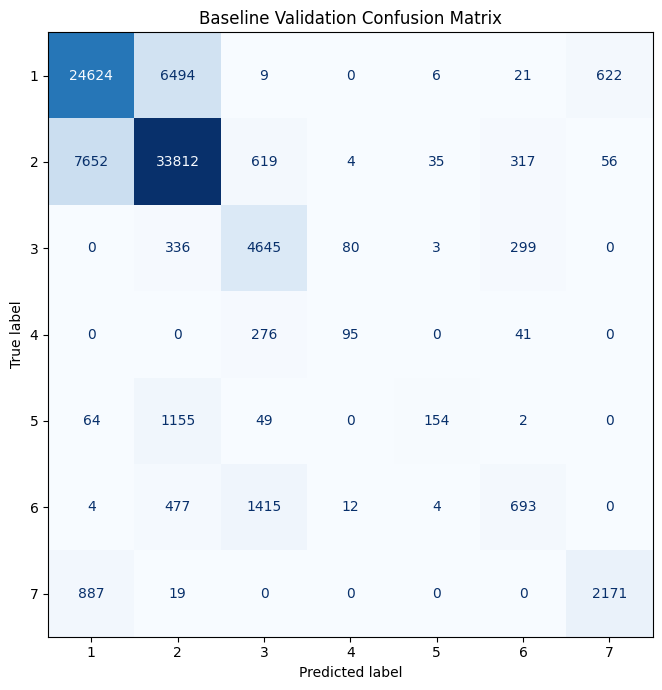

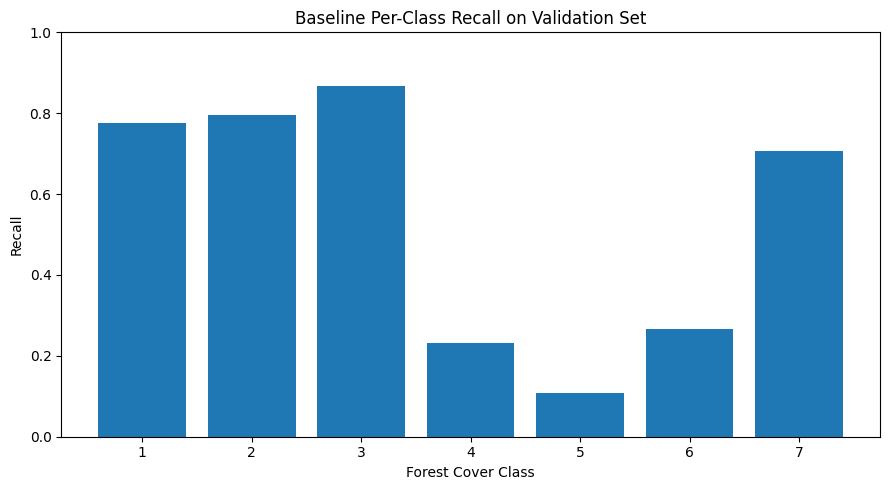


Validation evaluation completed.


In [8]:
#evaluating baseline on the validation set

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
from scipy.stats import gmean

def get_predictions(model, loader):
    model.eval()
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for features, labels in loader:
            features = features.to(device)

            logits = model(features)
            predictions = logits.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    return np.array(all_labels), np.array(all_predictions)

y_val_true, y_val_pred = get_predictions(
    baseline_model, val_loader
)

val_accuracy = accuracy_score(y_val_true, y_val_pred)

val_macro_f1 = f1_score(
    y_val_true,
    y_val_pred,
    average="macro",
    zero_division=0
)

val_weighted_f1 = f1_score(
    y_val_true,
    y_val_pred,
    average="weighted",
    zero_division=0
)

class_recalls = recall_score(
    y_val_true,
    y_val_pred,
    labels=np.arange(7),
    average=None,
    zero_division=0
)

val_gmean = gmean(class_recalls)

print("BASELINE VALIDATION RESULTS")
print("-" * 50)
print(f"Accuracy      : {val_accuracy:.4f}")
print(f"Macro-F1      : {val_macro_f1:.4f}")
print(f"Weighted F1   : {val_weighted_f1:.4f}")
print(f"G-mean recall : {val_gmean:.4f}")

report = classification_report(
    y_val_true,
    y_val_pred,
    labels=np.arange(7),
    target_names=[f"Class {i}" for i in range(1, 8)],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T
print("\nCLASSIFICATION REPORT")
display(report_df.round(4))

cm = confusion_matrix(
    y_val_true,
    y_val_pred,
    labels=np.arange(7)
)

fig, ax = plt.subplots(figsize=(8, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(1, 8)
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Baseline Validation Confusion Matrix")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(
    np.arange(1, 8),
    class_recalls
)
plt.xticks(np.arange(1, 8))
plt.ylim(0, 1)
plt.xlabel("Forest Cover Class")
plt.ylabel("Recall")
plt.title("Baseline Per-Class Recall on Validation Set")
plt.tight_layout()
plt.show()

print("\nValidation evaluation completed.")

In [9]:
#implementing and testing the SAM optimizer

import torch
import torch.nn as nn

class SAM:
    def __init__(
        self,
        params,
        base_optimizer,
        rho=0.05,
        adaptive=False,
        **kwargs
    ):
        self.params = list(params)
        self.rho = rho
        self.adaptive = adaptive

        self.base_optimizer = base_optimizer(
            self.params, **kwargs
        )

        self.param_groups = self.base_optimizer.param_groups
        self.state = self.base_optimizer.state

    @torch.no_grad()
    def first_step(self, zero_grad=False):
        grad_norm = self._grad_norm()

        for p in self.params:
            if p.grad is None:
                continue

            scale = self.rho / (grad_norm + 1e-12)

            if self.adaptive:
                scale = scale * p.abs()

            e_w = p.grad * scale.to(p)
            p.add_(e_w)
            self.state[p]["sam_e_w"] = e_w

        if zero_grad:
            self.zero_grad()

    @torch.no_grad()
    def second_step(self, zero_grad=False):
        for p in self.params:
            if p.grad is None:
                continue

            e_w = self.state[p].pop("sam_e_w", None)
            if e_w is not None:
                p.sub_(e_w)

        self.base_optimizer.step()

        if zero_grad:
            self.zero_grad()

    @torch.no_grad()
    def _grad_norm(self):
        norms = [
            (p.grad.norm(2))
            for p in self.params
            if p.grad is not None
        ]

        if not norms:
            return torch.tensor(0.0)

        return torch.norm(torch.stack(norms), 2)

    def zero_grad(self):
        self.base_optimizer.zero_grad()

sam_test_model = CoverTypeMLP().to(device)

sam_test_optimizer = SAM(
    sam_test_model.parameters(),
    torch.optim.SGD,
    rho=0.05,
    lr=0.01,
    momentum=0.9,
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss()

features, labels = next(iter(train_loader))
features = features[:128].to(device)
labels = labels[:128].to(device)

params_before = [
    p.detach().clone()
    for p in sam_test_model.parameters()
]

#first gradient step
sam_test_optimizer.zero_grad()
loss = criterion(sam_test_model(features), labels)
loss.backward()
sam_test_optimizer.first_step(zero_grad=True)

#second gradient step at perturbed parameters
criterion(sam_test_model(features), labels).backward()
sam_test_optimizer.second_step(zero_grad=True)

params_after = list(sam_test_model.parameters())

changed = any(
    not torch.allclose(before, after.detach())
    for before, after in zip(params_before, params_after)
)

print("SAM implementation test")
print("-" * 40)
print(f"Initial batch loss: {loss.item():.4f}")
print(f"Parameters updated: {changed}")
print(f"Perturbation radius rho: {sam_test_optimizer.rho}")

assert changed, "SAM did not update model parameters."

print("\nSAM optimizer test passed.")

SAM implementation test
----------------------------------------
Initial batch loss: 1.9182
Parameters updated: True
Perturbation radius rho: 0.05

SAM optimizer test passed.


Epoch 1/5 | Train Loss: 0.8860 | Train Acc: 0.6535 | Val Loss: 0.6785 | Val Acc: 0.7256
Epoch 2/5 | Train Loss: 0.6516 | Train Acc: 0.7324 | Val Loss: 0.6313 | Val Acc: 0.7370
Epoch 3/5 | Train Loss: 0.6167 | Train Acc: 0.7414 | Val Loss: 0.6039 | Val Acc: 0.7447
Epoch 4/5 | Train Loss: 0.5936 | Train Acc: 0.7486 | Val Loss: 0.5850 | Val Acc: 0.7524
Epoch 5/5 | Train Loss: 0.5757 | Train Acc: 0.7563 | Val Loss: 0.5693 | Val Acc: 0.7574

SAM training time: 0.64 minutes
Best SAM validation loss: 0.5693


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.885957,0.653522,0.678529,0.725629
1,2,0.651595,0.732448,0.631289,0.737023
2,3,0.616701,0.741390,0.603941,0.744653
3,4,0.593594,0.748597,0.584950,0.752421
4,5,0.575716,0.756305,0.569314,0.757401


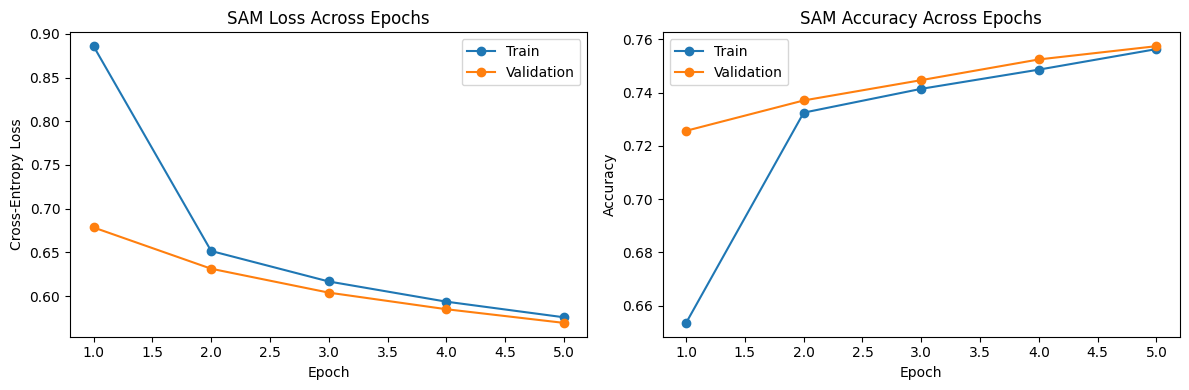


SAM baseline training completed.


In [10]:
#training the neural network using SAM

import time
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

sam_model = CoverTypeMLP().to(device)

sam_optimizer = SAM(
    sam_model.parameters(),
    torch.optim.SGD,
    rho=0.05,
    lr=0.01,
    momentum=0.9,
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss()
SAM_EPOCHS = 5

sam_history = []
best_sam_val_loss = float("inf")
best_sam_state = None

start_time = time.time()

for epoch in range(SAM_EPOCHS):
    sam_model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for features, labels in train_loader:
        features = features.to(device)
        labels = labels.to(device)

        #first pass: calculating gradient at original weights
        sam_optimizer.zero_grad()
        logits = sam_model(features)
        loss = criterion(logits, labels)
        loss.backward()

        sam_optimizer.first_step(zero_grad=True)

        #second pass: calculating gradient at perturbed weights
        perturbed_logits = sam_model(features)
        perturbed_loss = criterion(perturbed_logits, labels)
        perturbed_loss.backward()

        #restoring weights and updating original parameters
        sam_optimizer.second_step(zero_grad=True)

        #record predictions from the original weight forward pass
        running_loss += loss.item() * labels.size(0)
        train_correct += (
            logits.argmax(dim=1) == labels
        ).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_accuracy = train_correct / train_total

    sam_model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for features, labels in val_loader:
            features = features.to(device)
            labels = labels.to(device)

            logits = sam_model(features)
            loss = criterion(logits, labels)

            val_running_loss += loss.item() * labels.size(0)
            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = val_correct / val_total

    sam_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    if val_loss < best_sam_val_loss:
        best_sam_val_loss = val_loss
        best_sam_state = copy.deepcopy(
            sam_model.state_dict()
        )

    print(
        f"Epoch {epoch + 1}/{SAM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

elapsed = time.time() - start_time

sam_model.load_state_dict(best_sam_state)
sam_history_df = pd.DataFrame(sam_history)

print(f"\nSAM training time: {elapsed / 60:.2f} minutes")
print(f"Best SAM validation loss: {best_sam_val_loss:.4f}")

display(sam_history_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    sam_history_df["epoch"],
    sam_history_df["train_loss"],
    marker="o", label="Train"
)
axes[0].plot(
    sam_history_df["epoch"],
    sam_history_df["val_loss"],
    marker="o", label="Validation"
)
axes[0].set_title("SAM Loss Across Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()

axes[1].plot(
    sam_history_df["epoch"],
    sam_history_df["train_accuracy"],
    marker="o", label="Train"
)
axes[1].plot(
    sam_history_df["epoch"],
    sam_history_df["val_accuracy"],
    marker="o", label="Validation"
)
axes[1].set_title("SAM Accuracy Across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

print("\nSAM baseline training completed.")

VALIDATION METRICS COMPARISON


,Accuracy,Macro-F1,Weighted-F1,G-mean
Ordinary SGD,0.7595,0.5559,0.7522,0.4249
Standard SAM,0.7574,0.5533,0.7485,0.4126



PER-CLASS RECALL COMPARISON


,Class,Ordinary SGD,Standard SAM
0,1,0.7749,0.7498
1,2,0.7957,0.8161
2,3,0.8661,0.8628
3,4,0.2306,0.3277
4,5,0.1081,0.0758
5,6,0.2660,0.2369
6,7,0.7056,0.6552


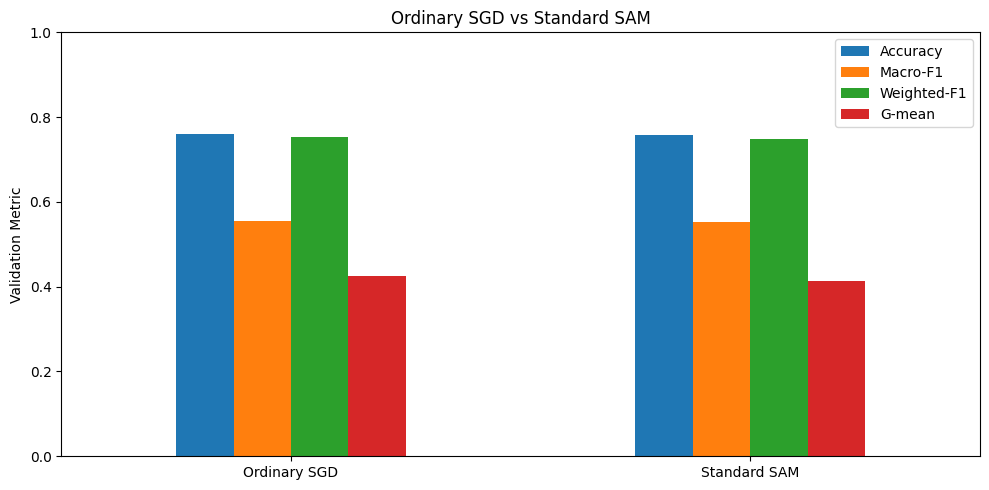

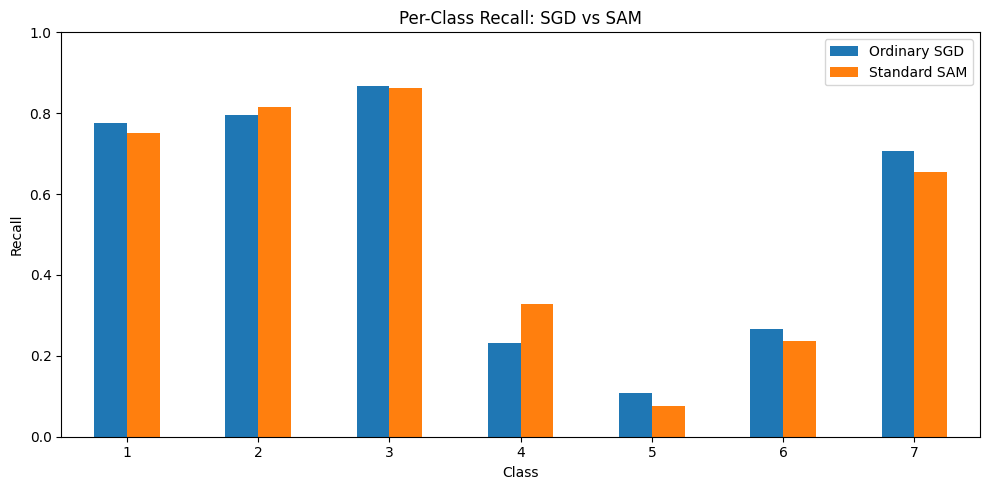


Comparison completed.


In [11]:
#comparing ordinary SGD and SAM on validation data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)
from scipy.stats import gmean

def evaluate_model(model, loader):
    y_true, y_pred = get_predictions(model, loader)

    recalls = recall_score(
        y_true,
        y_pred,
        labels=np.arange(7),
        average=None,
        zero_division=0
    )

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(
            y_true, y_pred,
            labels=np.arange(7),
            average="macro",
            zero_division=0
        ),
        "Weighted-F1": f1_score(
            y_true, y_pred,
            average="weighted",
            zero_division=0
        ),
        "G-mean": gmean(recalls)
    }

    return metrics, recalls


sgd_metrics, sgd_recalls = evaluate_model(
    baseline_model, val_loader
)

sam_metrics, sam_recalls = evaluate_model(
    sam_model, val_loader
)

comparison_df = pd.DataFrame(
    [sgd_metrics, sam_metrics],
    index=["Ordinary SGD", "Standard SAM"]
)

print("VALIDATION METRICS COMPARISON")
display(comparison_df.round(4))

#per class recall comparison
recall_df = pd.DataFrame({
    "Class": np.arange(1, 8),
    "Ordinary SGD": sgd_recalls,
    "Standard SAM": sam_recalls
})

print("\nPER-CLASS RECALL COMPARISON")
display(recall_df.round(4))

#plot overall metrics
comparison_df.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)
plt.title("Ordinary SGD vs Standard SAM")
plt.ylabel("Validation Metric")
plt.tight_layout()
plt.show()

#plot per class recall
recall_df.plot(
    x="Class",
    y=["Ordinary SGD", "Standard SAM"],
    kind="bar",
    figsize=(10, 5),
    rot=0
)
plt.title("Per-Class Recall: SGD vs SAM")
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

print("\nComparison completed.")

In [12]:
import copy
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

#giving minority classes higher loss weights
#calculating weights from the original natural training labels
class_counts = torch.bincount(y_train_tensor, minlength=7).float()
class_weights = class_counts.sum() / (7 * class_counts)
class_weights = class_weights / class_weights.mean()
class_weights = class_weights.to(device)

print("Class counts:", class_counts.cpu().numpy())
print("Class weights:", class_weights.cpu().numpy())

def train_class_targeted_sam(
    model,
    train_loader,
    val_loader,
    epochs=5,
    lr=0.01,
    rho=0.05
):
    model = model.to(device)

    optimizer = SAM(
        model.parameters(),
        torch.optim.SGD,
        rho=rho,
        lr=lr,
        momentum=0.9,
        weight_decay=1e-4
    )

    #weighted loss makes errors on rarer classes matter more
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    history = []
    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        total_samples = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            #first SAM pass
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.first_step(zero_grad=True)

            #second SAM pass at perturbed weights
            logits_perturbed = model(xb)
            loss_perturbed = criterion(logits_perturbed, yb)
            loss_perturbed.backward()
            optimizer.second_step(zero_grad=True)

            running_loss += loss.item() * len(yb)
            total_samples += len(yb)

        #validation uses the ordinary, unweighted loss.
        model.eval()
        val_loss_sum = 0.0
        val_samples = 0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb.to(device)
                logits = model(xb)
                val_loss_sum += nn.functional.cross_entropy(
                    logits, yb, reduction="sum"
                ).item()
                val_samples += len(yb)

        train_loss = running_loss / max(total_samples, 1)
        val_loss = val_loss_sum / max(val_samples, 1)

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Validation loss: {val_loss:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_state

#start from the same initial weights as the ordinary SAM model so the comparison is less affected by random initialization.
targeted_model = CoverTypeMLP().to(device)
targeted_model.load_state_dict(copy.deepcopy(best_sam_state))

targeted_model, targeted_history_df, best_targeted_state = (
    train_class_targeted_sam(
        targeted_model,
        train_loader,
        val_loader,
        epochs=5
    )
)

print("\nClass-targeted SAM training complete.")

Class counts: [137696. 184145.  23240.   1786.   6170.  11289.  13331.]
Class weights: [0.05400671 0.04038398 0.31998745 4.1637783  1.2052687  0.6587393
 0.5578357 ]
Epoch 1/5 | Train loss: 0.6705 | Validation loss: 0.8009
Epoch 2/5 | Train loss: 0.6119 | Validation loss: 0.7697
Epoch 3/5 | Train loss: 0.5818 | Validation loss: 0.7553
Epoch 4/5 | Train loss: 0.5609 | Validation loss: 0.7549
Epoch 5/5 | Train loss: 0.5429 | Validation loss: 0.7457

Class-targeted SAM training complete.


VALIDATION METRICS


,Accuracy,Macro-F1,Weighted-F1,G-mean
Model,,,,
Ordinary SGD,0.7595,0.5559,0.7522,0.4249
Standard SAM,0.7574,0.5533,0.7485,0.4126
Class-Targeted SAM,0.6705,0.5604,0.6921,0.7621



PER-CLASS RECALL


,Class,Ordinary SGD,Standard SAM,Class-Targeted SAM
0,1,0.7749,0.7498,0.7075
1,2,0.7957,0.8161,0.6137
2,3,0.8661,0.8628,0.6638
3,4,0.2306,0.3277,0.9320
4,5,0.1081,0.0758,0.8764
5,6,0.2660,0.2369,0.6599
6,7,0.7056,0.6552,0.9613


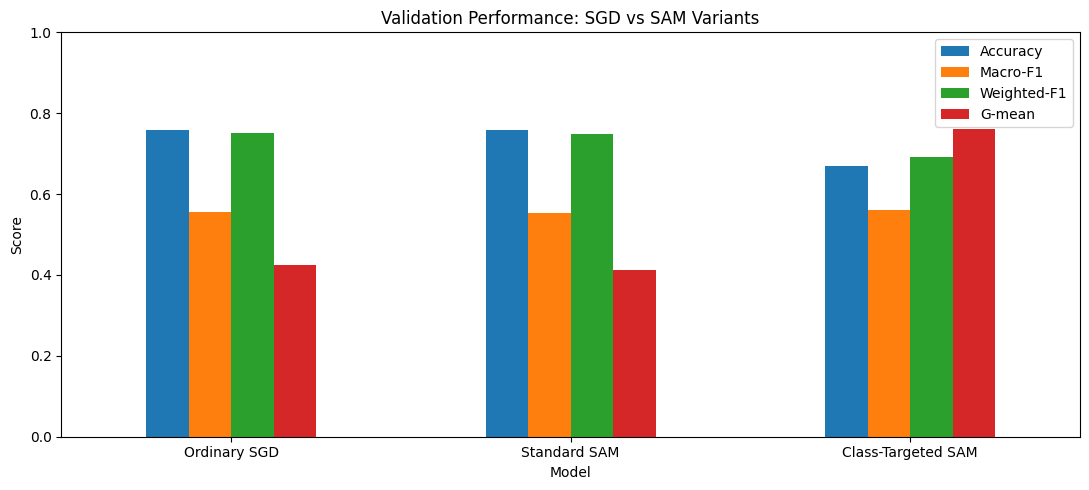

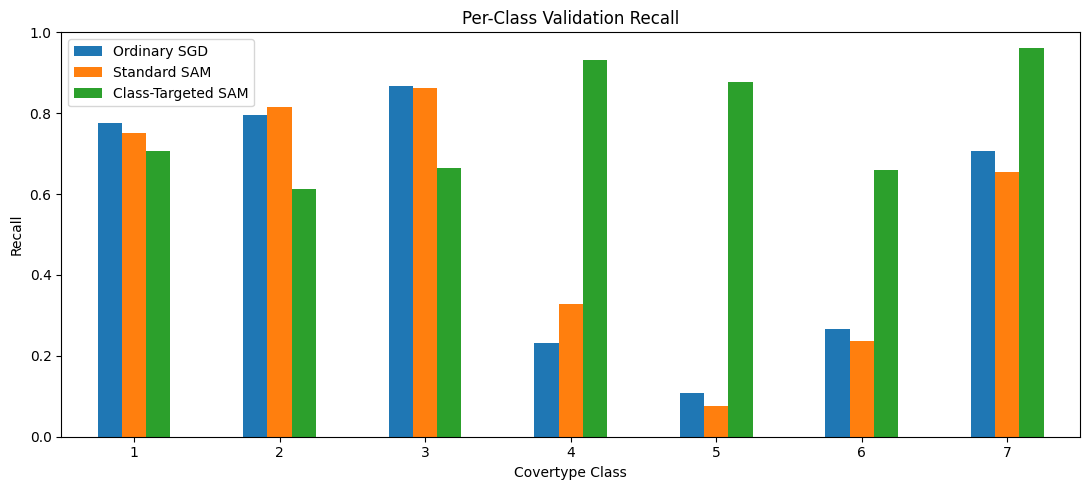

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, recall_score
from scipy.stats import gmean

def evaluate_model(model, loader):
    y_true, y_pred = get_predictions(model, loader)

    recalls = recall_score(
        y_true,
        y_pred,
        labels=np.arange(7),
        average=None,
        zero_division=0
    )

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(
            y_true, y_pred, labels=np.arange(7),
            average="macro", zero_division=0
        ),
        "Weighted-F1": f1_score(
            y_true, y_pred, labels=np.arange(7),
            average="weighted", zero_division=0
        ),
        "G-mean": gmean(recalls)
    }

    return metrics, recalls


models = {
    "Ordinary SGD": baseline_model,
    "Standard SAM": sam_model,
    "Class-Targeted SAM": targeted_model
}

results = {}
recall_results = {}

for name, model in models.items():
    metrics, recalls = evaluate_model(model, val_loader)
    results[name] = metrics
    recall_results[name] = recalls

comparison_df = pd.DataFrame(results).T
comparison_df.index.name = "Model"

print("VALIDATION METRICS")
display(comparison_df.round(4))

recall_df = pd.DataFrame({
    "Class": np.arange(1, 8),
    "Ordinary SGD": recall_results["Ordinary SGD"],
    "Standard SAM": recall_results["Standard SAM"],
    "Class-Targeted SAM": recall_results["Class-Targeted SAM"]
})

print("\nPER-CLASS RECALL")
display(recall_df.round(4))

#plot overall metrics
comparison_df.plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1),
    rot=0
)
plt.title("Validation Performance: SGD vs SAM Variants")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

#plot recall by class
recall_df.set_index("Class").plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1),
    rot=0
)
plt.title("Per-Class Validation Recall")
plt.ylabel("Recall")
plt.xlabel("Covertype Class")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

In [14]:
import torch
import pandas as pd

#using one fixed validation batch for a consistent preliminary comparison
xb, yb = next(iter(val_loader))
xb = xb[:256].to(device)
yb = yb[:256].to(device)

def estimate_curvature(model, xb, yb, iterations=8):
    model.eval()
    params = [p for p in model.parameters() if p.requires_grad]

    vector = [torch.randn_like(p) for p in params]
    norm = torch.sqrt(sum((v * v).sum() for v in vector))
    vector = [v / (norm + 1e-12) for v in vector]

    eigenvalue = None

    for _ in range(iterations):
        model.zero_grad(set_to_none=True)

        logits = model(xb)
        loss = torch.nn.functional.cross_entropy(logits, yb)

        first_grads = torch.autograd.grad(
            loss, params, create_graph=True
        )

        #compute Hessian-vector product: H @ vector
        dot_product = sum(
            (g * v).sum()
            for g, v in zip(first_grads, vector)
        )

        hvps = torch.autograd.grad(dot_product, params)

        norm = torch.sqrt(
            sum((h * h).sum() for h in hvps)
        )

        if norm.item() < 1e-12:
            eigenvalue = 0.0
            break

        vector = [h / norm for h in hvps]

        #rayleigh quotient approximation
        eigenvalue = sum(
            (v * h).sum()
            for v, h in zip(vector, hvps)
        ).item()

    model.zero_grad(set_to_none=True)

    return {
        "Signed Rayleigh Estimate": eigenvalue,
        "Curvature Magnitude": abs(eigenvalue)
    }

curvature_results = {}

for name, model in models.items():
    curvature_results[name] = estimate_curvature(model, xb, yb)
    print(name, curvature_results[name])

curvature_df = pd.DataFrame(curvature_results).T
curvature_df.index.name = "Model"

print("\nPRELIMINARY CURVATURE ESTIMATES")
display(curvature_df.round(6))

Ordinary SGD {'Signed Rayleigh Estimate': 18.56041717529297, 'Curvature Magnitude': 18.56041717529297}
Standard SAM {'Signed Rayleigh Estimate': 9.200997352600098, 'Curvature Magnitude': 9.200997352600098}
Class-Targeted SAM {'Signed Rayleigh Estimate': 17.404300689697266, 'Curvature Magnitude': 17.404300689697266}

PRELIMINARY CURVATURE ESTIMATES


,Signed Rayleigh Estimate,Curvature Magnitude
Model,,
Ordinary SGD,18.560417,18.560417
Standard SAM,9.200997,9.200997
Class-Targeted SAM,17.404301,17.404301


In [15]:

import torch
import torch.nn as nn
import numpy as np
import pandas as pd

def extract_penultimate_features(model, loader):
    model.eval()

    linear_layers = [
        module for module in model.modules()
        if isinstance(module, nn.Linear)
    ]

    if len(linear_layers) < 2:
        raise ValueError(
            "Could not identify the penultimate linear layer."
        )

    # Capture the output of the last hidden linear layer.
    feature_layer = linear_layers[-2]
    captured = []

    def hook_fn(module, inputs, output):
        captured.append(output.detach())

    handle = feature_layer.register_forward_hook(hook_fn)

    all_features = []
    all_labels = []

    try:
        with torch.no_grad():
            for xb, yb in loader:
                captured.clear()
                xb = xb.to(device)
                _ = model(xb)

                if not captured:
                    raise RuntimeError("Feature extraction hook did not run.")

                all_features.append(captured[-1].cpu())
                all_labels.append(yb.cpu())
    finally:
        handle.remove()

    return torch.cat(all_features), torch.cat(all_labels)


def calculate_nc1(features, labels, num_classes=7):
    features = features.float()
    labels = labels.long()

    overall_mean = features.mean(dim=0)
    within_scatter = torch.tensor(0.0)
    between_scatter = torch.tensor(0.0)

    for class_id in range(num_classes):
        class_features = features[labels == class_id]

        if len(class_features) == 0:
            continue

        class_mean = class_features.mean(dim=0)

        #total squared deviation within this class
        within_scatter += (
            (class_features - class_mean) ** 2
        ).sum()

        #between class scatter, weighted by class size
        between_scatter += len(class_features) * (
            (class_mean - overall_mean) ** 2
        ).sum()

    nc1 = (
        within_scatter / (between_scatter + 1e-12)
    ).item()

    return nc1

nc_results = {}

for name, model in models.items():
    features, feature_labels = extract_penultimate_features(
        model, val_loader
    )

    nc1 = calculate_nc1(features, feature_labels)
    nc_results[name] = nc1

    print(
        f"{name}: NC1 = {nc1:.6f} | "
        f"Feature shape = {tuple(features.shape)}"
    )

nc_df = pd.DataFrame.from_dict(
    nc_results,
    orient="index",
    columns=["NC1"]
)
nc_df.index.name = "Model"

print("\nPRELIMINARY NEURAL-COLLAPSE METRIC")
display(nc_df.round(6))

Ordinary SGD: NC1 = 1.282206 | Feature shape = (87152, 64)
Standard SAM: NC1 = 1.232917 | Feature shape = (87152, 64)
Class-Targeted SAM: NC1 = 1.433255 | Feature shape = (87152, 64)

PRELIMINARY NEURAL-COLLAPSE METRIC


,NC1
Model,
Ordinary SGD,1.282206
Standard SAM,1.232917
Class-Targeted SAM,1.433255


In [16]:
final_results_df = pd.DataFrame({
    "Accuracy": [
        comparison_df.loc["Ordinary SGD", "Accuracy"],
        comparison_df.loc["Standard SAM", "Accuracy"],
        comparison_df.loc["Class-Targeted SAM", "Accuracy"]
    ],
    "Macro-F1": [
        comparison_df.loc["Ordinary SGD", "Macro-F1"],
        comparison_df.loc["Standard SAM", "Macro-F1"],
        comparison_df.loc["Class-Targeted SAM", "Macro-F1"]
    ],
    "Weighted-F1": [
        comparison_df.loc["Ordinary SGD", "Weighted-F1"],
        comparison_df.loc["Standard SAM", "Weighted-F1"],
        comparison_df.loc["Class-Targeted SAM", "Weighted-F1"]
    ],
    "G-mean": [
        comparison_df.loc["Ordinary SGD", "G-mean"],
        comparison_df.loc["Standard SAM", "G-mean"],
        comparison_df.loc["Class-Targeted SAM", "G-mean"]
    ],
    "Curvature Magnitude": [
        curvature_df.loc["Ordinary SGD", "Curvature Magnitude"],
        curvature_df.loc["Standard SAM", "Curvature Magnitude"],
        curvature_df.loc["Class-Targeted SAM", "Curvature Magnitude"]
    ],
    "NC1": [
        nc_df.loc["Ordinary SGD", "NC1"],
        nc_df.loc["Standard SAM", "NC1"],
        nc_df.loc["Class-Targeted SAM", "NC1"]
    ]
}, index=["Ordinary SGD", "Standard SAM", "Class-Targeted SAM"])

display(final_results_df.round(4))

final_results_df.to_csv(
    "review1_preliminary_results.csv",
    index=True
)

print("Saved: review1_preliminary_results.csv")

,Accuracy,Macro-F1,Weighted-F1,G-mean,Curvature Magnitude,NC1
Ordinary SGD,0.7595,0.5559,0.7522,0.4249,18.5604,1.2822
Standard SAM,0.7574,0.5533,0.7485,0.4126,9.2010,1.2329
Class-Targeted SAM,0.6705,0.5604,0.6921,0.7621,17.4043,1.4333


Saved: review1_preliminary_results.csv


In [17]:
from google.colab import files

files.download("review1_preliminary_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>